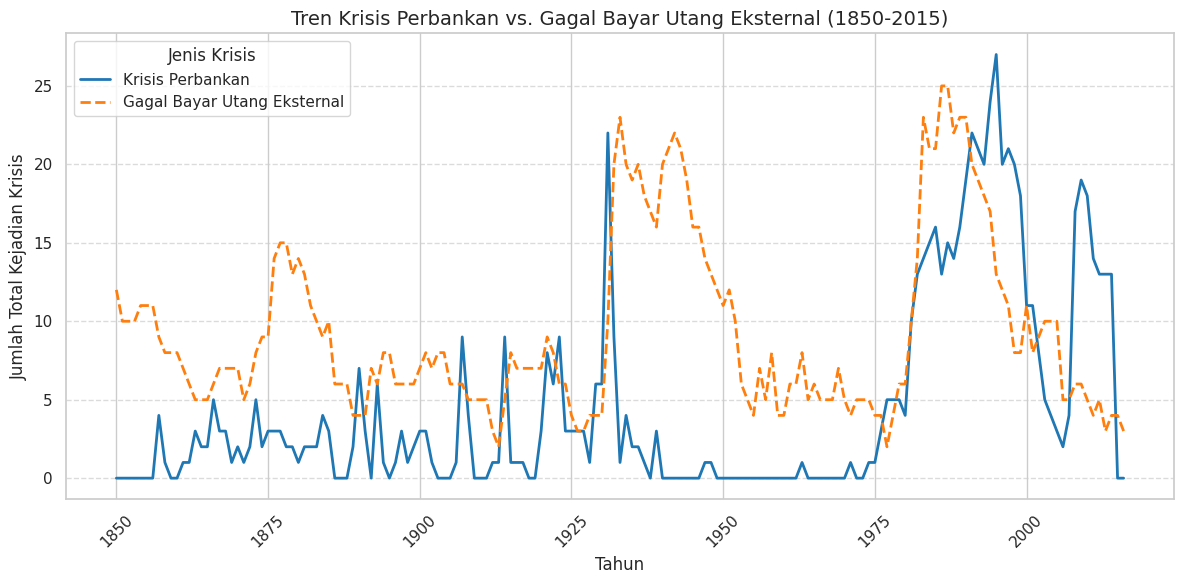

In [18]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. BACA DATA (Pastikan nama file sesuai)
df = pd.read_excel("20160923_global_crisis_data.xlsx")

# 2. PEMBERSIHAN DATA DAN KOLOM
df.columns = df.columns.str.strip() # Bersihkan spasi pada nama kolom
df = df.iloc[1:].copy() # Hapus baris metadata pertama

# Ganti nama kolom utang yang panjang
debt_col_original = 'SOVEREIGN EXTERNAL DEBT 1: DEFAULT and RESTRUCTURINGS, 1800-2012--Does not include defaults on WWI debt to United States and United Kingdom and post-1975 defaults on Official External Creditors'
df = df.rename(columns={debt_col_original: 'External_Debt_Default'})

# Kolom krisis yang akan diproses
crisis_cols = ['Banking Crisis', 'External_Debt_Default']

# Konversi ke numerik (0 atau 1)
for col in crisis_cols:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# Konversi kolom Tahun ke integer
df['Year'] = pd.to_numeric(df['Year'], errors='coerce').fillna(0).astype(int)

# 3. AGREGRASI DATA
# Hitung total kejadian krisis per tahun
yearly_crisis = df.groupby('Year')[crisis_cols].sum().reset_index()

# Filter data untuk periode 1850-2015
yearly_crisis = yearly_crisis[yearly_crisis['Year'] >= 1850].copy()

# 4. PEMBUATAN VISUALISASI DENGAN MATPLOTLIB
plt.figure(figsize=(12, 6))

# Plot Garis 1: Krisis Perbankan (Biru Solid)
plt.plot(yearly_crisis['Year'], yearly_crisis['Banking Crisis'],
         label='Krisis Perbankan', color='#1f77b4', linewidth=2)

# Plot Garis 2: Gagal Bayar Utang Eksternal (Oranye Putus-putus)
plt.plot(yearly_crisis['Year'], yearly_crisis['External_Debt_Default'],
         label='Gagal Bayar Utang Eksternal', color='#ff7f0e', linewidth=2, linestyle='--')

# Judul, Label, dan Estetika
plt.title('Tren Krisis Perbankan vs. Gagal Bayar Utang Eksternal (1850-2015)', fontsize=14)
plt.xlabel('Tahun', fontsize=12)
plt.ylabel('Jumlah Total Kejadian Krisis', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.legend(title='Jenis Krisis')
plt.xticks(rotation=45)
plt.tight_layout()

# Simpan gambar
plt.savefig('tren_krisis_global.png')
# plt.show() # Jangan digunakan di lingkungan ini